In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\HP\Downloads\Dataset_digital_life_impact_on_habits\social_media_sleep_stress_productivity_11000.csv"
)

print(df.shape)
df.head()

(11000, 10)


,user_id,age,daily_screen_time_hours,social_media_hours,sleep_hours,exercise_minutes,study_work_hours,productivity_score,stress_level,platform
0,1,44,2.39,1.93,8.46,61,3.73,33.86,Low,YouTube
1,2,30,7.22,5.24,7.34,28,6.80,85.32,Low,YouTube
2,3,23,2.56,4.64,4.69,8,4.47,60.07,High,YouTube
3,4,36,8.75,4.89,5.05,53,9.53,36.46,Medium,LinkedIn
4,5,34,10.96,2.77,7.12,83,7.01,32.93,Medium,Instagram


In [3]:
import matplotlib.pyplot as plt

In [4]:
X = df["sleep_hours"].tolist()
Y = df["productivity_score"].tolist()

print("Total observations:", len(X))

Total observations: 11000


In [5]:
import random

# Keep only complete X-Y pairs
pairs = []

for x, y in zip(X, Y):
    if pd.notna(x) and pd.notna(y):
        pairs.append((float(x), float(y)))

# Shuffle reproducibly
random.seed(42)
random.shuffle(pairs)

split_index = int(0.8 * len(pairs))

train_data = pairs[:split_index]
test_data = pairs[split_index:]

X_train = [row[0] for row in train_data]
Y_train = [row[1] for row in train_data]

X_test = [row[0] for row in test_data]
Y_test = [row[1] for row in test_data]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 8800
Testing observations: 2200


In [6]:
n = len(X_train)

mean_X = sum(X_train) / n
mean_Y = sum(Y_train) / n

print("Mean sleep hours:", mean_X)
print("Mean productivity:", mean_Y)

Mean sleep hours: 5.985910227272727
Mean productivity: 50.40452159090909


In [7]:
numerator = 0
denominator = 0

for i in range(n):
    numerator += (
        (X_train[i] - mean_X) *
        (Y_train[i] - mean_Y)
    )

    denominator += (
        (X_train[i] - mean_X) ** 2
    )

if denominator == 0:
    raise ValueError("Cannot fit regression: X has no variation.")

b1 = numerator / denominator

print("Slope:", b1)

Slope: 0.17377917822658753


In [8]:
b0 = mean_Y - b1 * mean_X

print("Intercept:", b0)

Intercept: 49.364295030675514


In [9]:
print(f"Regression equation: Y = {b0:.4f} + ({b1:.4f})X")

Regression equation: Y = 49.3643 + (0.1738)X


In [10]:
Y_pred = []

for x in X_test:
    prediction = b0 + b1 * x
    Y_pred.append(prediction)

print("First five predictions:")

for i in range(5):
    print(
        "Sleep:", X_test[i],
        "Actual:", Y_test[i],
        "Predicted:", round(Y_pred[i], 2)
    )

First five predictions:
Sleep: 6.75 Actual: 16.73 Predicted: 50.54
Sleep: 6.71 Actual: 34.84 Predicted: 50.53
Sleep: 6.24 Actual: 70.49 Predicted: 50.45
Sleep: 7.85 Actual: 54.97 Predicted: 50.73
Sleep: 6.08 Actual: 52.25 Predicted: 50.42


In [11]:
sleep = 7

predicted_productivity = b0 + b1 * sleep

print(
    "Predicted productivity:",
    round(predicted_productivity, 2)
)

Predicted productivity: 50.58


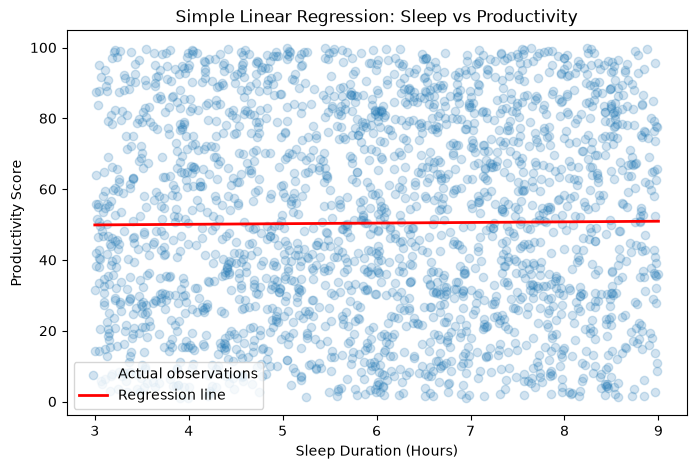

In [12]:
plt.figure(figsize=(8, 5))
# Actual test observations
plt.scatter(
    X_test,
    Y_test,
    alpha=0.2,
    label="Actual observations"
)

# Regression line
x_line = sorted(X_test)
y_line = [b0 + b1 * x for x in x_line]

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression line"
)

plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Productivity Score")
plt.title("Simple Linear Regression: Sleep vs Productivity")

plt.legend()
plt.show()

In [13]:

import math
import pandas as pd

# Calculate prediction errors
errors = []
absolute_errors = []
squared_errors = []

for i in range(len(Y_test)):
    error = Y_test[i] - Y_pred[i]

    errors.append(error)
    absolute_errors.append(abs(error))
    squared_errors.append(error ** 2)

# Calculate evaluation metrics
n = len(Y_test)

MAE = sum(absolute_errors) / n
MSE = sum(squared_errors) / n
RMSE = math.sqrt(MSE)

# R-squared calculation
y_mean = sum(Y_test) / n

SS_res = sum(squared_errors)
SS_tot = sum((y - y_mean) ** 2 for y in Y_test)

R2 = 1 - (SS_res / SS_tot)

# Display results
evaluation = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R-squared"],
    "Value": [MAE, MSE, RMSE, R2]
})

display(evaluation.round(4))


,Metric,Value
0,MAE,25.1429
1,MSE,832.6393
2,RMSE,28.8555
3,R-squared,-0.0007


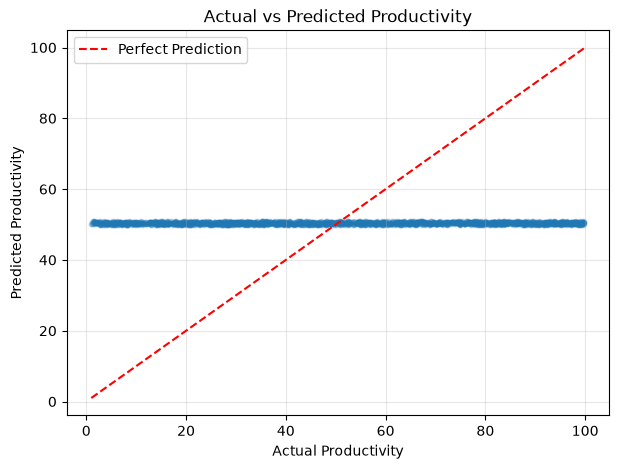

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(Y_test, Y_pred, alpha=0.25, s=10)

minimum = min(min(Y_test), min(Y_pred))
maximum = max(max(Y_test), max(Y_pred))

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Productivity")
plt.ylabel("Predicted Productivity")
plt.title("Actual vs Predicted Productivity")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

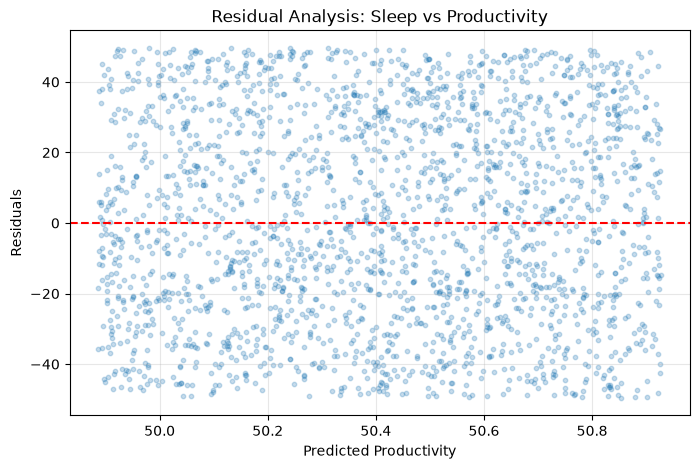

In [15]:

residuals = []

for i in range(len(Y_test)):
    error = Y_test[i] - Y_pred[i]
    residuals.append(error)

plt.figure(figsize=(8, 5))

plt.scatter(Y_pred, residuals, alpha=0.25, s=10)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Productivity")
plt.ylabel("Residuals")
plt.title("Residual Analysis: Sleep vs Productivity")
plt.grid(alpha=0.3)
plt.show()


In [16]:

import math
import pandas as pd

# Calculate mean productivity from training data
baseline_mean = sum(Y_train) / len(Y_train)

# Calculate baseline prediction errors
baseline_errors = []

for i in range(len(Y_test)):
    error = Y_test[i] - baseline_mean
    baseline_errors.append(error ** 2)

# Calculate baseline RMSE
baseline_MSE = sum(baseline_errors) / len(Y_test)
baseline_RMSE = math.sqrt(baseline_MSE)

# Compare models
comparison = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Sleep Linear Regression"
    ],
    "RMSE": [
        baseline_RMSE,
        RMSE
    ]
})

display(comparison.round(4))


,Model,RMSE
0,Mean Baseline,28.8652
1,Sleep Linear Regression,28.8555


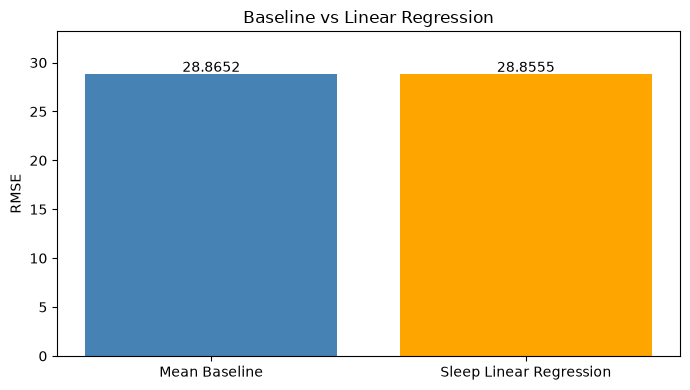

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    comparison["Model"],
    comparison["RMSE"],
    color=["steelblue", "orange"]
)

plt.ylabel("RMSE")
plt.title("Baseline vs Linear Regression")
plt.ylim(0, max(comparison["RMSE"]) * 1.15)

for i, value in enumerate(comparison["RMSE"]):
    plt.text(i, value + 0.2, f"{value:.4f}", ha="center")

plt.tight_layout()
plt.show()


In [18]:

summary = pd.DataFrame({
    "Parameter": [
        "Independent Variable",
        "Dependent Variable",
        "Training Records",
        "Testing Records",
        "Slope",
        "Intercept",
        "MAE",
        "MSE",
        "RMSE",
        "R-squared",
        "Baseline RMSE"
    ],
    "Value": [
        "Sleep Hours",
        "Productivity Score",
        len(X_train),
        len(X_test),
        round(b1, 4),
        round(b0, 4),
        round(MAE, 4),
        round(MSE, 4),
        round(RMSE, 4),
        round(R2, 4),
        round(baseline_RMSE, 4)
    ]
})

display(summary)


,Parameter,Value
0,Independent Variable,Sleep Hours
1,Dependent Variable,Productivity Score
2,Training Records,8800
3,Testing Records,2200
4,Slope,0.1738
5,Intercept,49.3643
6,MAE,25.1429
7,MSE,832.6393
8,RMSE,28.8555
9,R-squared,-0.0007


In [19]:

import numpy as np
import pandas as pd
import math

def simple_linear_regression(x_train, y_train, x_test, y_test):

    # Step 1: Calculate training means
    x_mean = sum(x_train) / len(x_train)
    y_mean = sum(y_train) / len(y_train)

    # Step 2: Calculate slope using OLS formula
    numerator = 0
    denominator = 0

    for i in range(len(x_train)):
        numerator += (x_train[i] - x_mean) * (y_train[i] - y_mean)
        denominator += (x_train[i] - x_mean) ** 2

    if denominator == 0:
        raise ValueError("Feature has no variation")

    b1 = numerator / denominator

    # Step 3: Calculate intercept
    b0 = y_mean - b1 * x_mean

    # Step 4: Predict productivity
    predictions = []

    for x in x_test:
        predictions.append(b0 + b1 * x)

    # Step 5: Calculate evaluation metrics
    n = len(y_test)

    absolute_error = 0
    squared_error = 0

    for i in range(n):
        error = y_test[i] - predictions[i]
        absolute_error += abs(error)
        squared_error += error ** 2

    MAE = absolute_error / n
    MSE = squared_error / n
    RMSE = math.sqrt(MSE)

    # Step 6: Calculate R-squared
    test_mean = sum(y_test) / n

    ss_total = sum(
        (y - test_mean) ** 2 for y in y_test
    )

    R2 = 1 - (squared_error / ss_total)

    return b0, b1, MAE, MSE, RMSE, R2


Total observations: 11000
Training records: 8800
Testing records: 2200

SIMPLE LINEAR REGRESSION RESULTS


,Feature,Intercept,Slope,MAE,MSE,RMSE,R2
0,sleep_hours,48.6794,0.3403,25.4089,852.5913,29.1992,-0.0008
1,daily_screen_time_hours,50.6656,0.0082,25.4169,852.1867,29.1922,-0.0003
2,social_media_hours,51.5235,-0.1894,25.4301,852.9934,29.2061,-0.0013
3,exercise_minutes,50.8581,-0.0023,25.4161,852.1777,29.1921,-0.0003
4,study_work_hours,51.0733,-0.0641,25.4186,852.3244,29.1946,-0.0005
5,age,51.7956,-0.0330,25.4133,852.0604,29.1901,-0.0002



Baseline RMSE: 29.1919

FINAL MODEL COMPARISON


,Feature,RMSE,RMSE Improvement,R2
5,age,29.1901,0.0018,-0.0002
3,exercise_minutes,29.1921,-0.0002,-0.0003
1,daily_screen_time_hours,29.1922,-0.0004,-0.0003
4,study_work_hours,29.1946,-0.0027,-0.0005
0,sleep_hours,29.1992,-0.0073,-0.0008
2,social_media_hours,29.2061,-0.0142,-0.0013


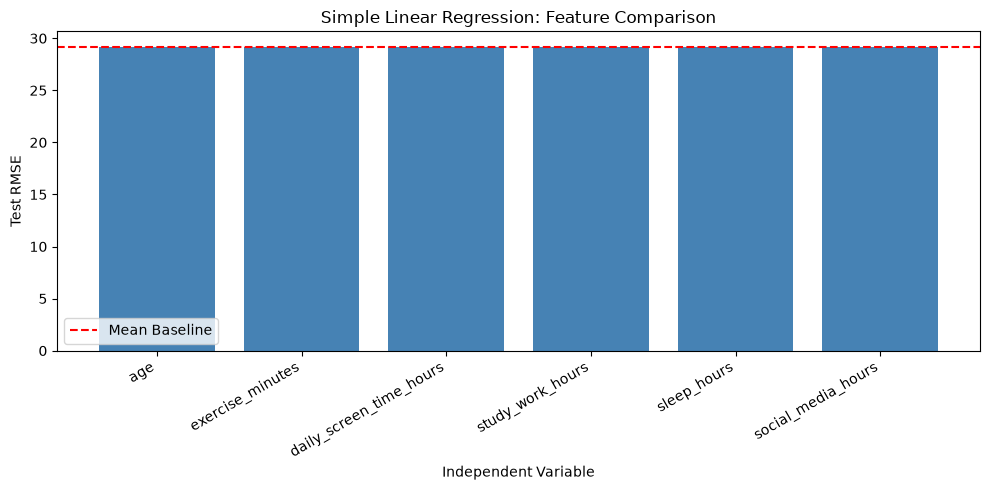

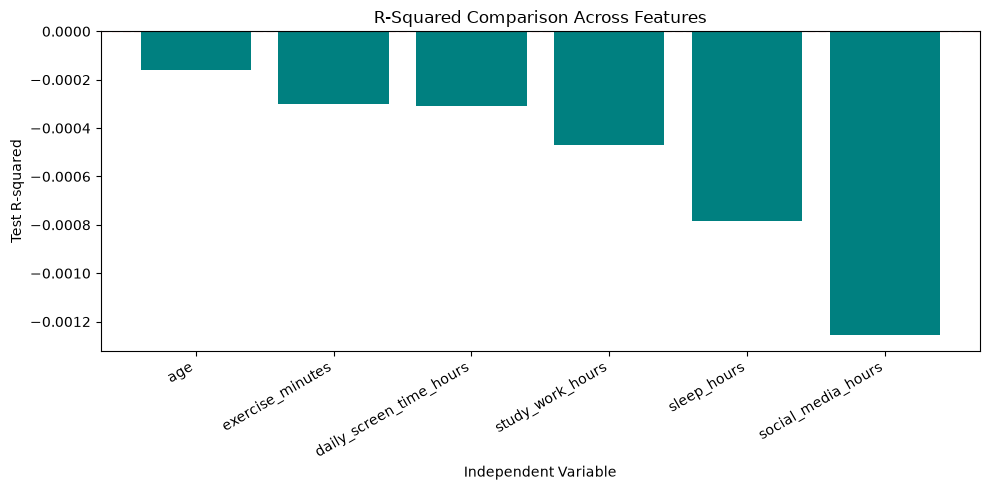


BEST INDIVIDUAL PREDICTOR
Feature: age
RMSE: 29.1901
R-squared: -0.0002
Best model outperforms the mean baseline.


In [26]:

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

# ==================================================
# STEP 1: SELECT FEATURES AND TARGET
# ==================================================

# df must contain your final cleaned dataset
features = [
    "sleep_hours",
    "daily_screen_time_hours",
    "social_media_hours",
    "exercise_minutes",
    "study_work_hours",
    "age"
]

target = "productivity_score"

# Remove rows with missing values in selected columns
data = df[features + [target]].dropna().copy()

print("Total observations:", len(data))

# ==================================================
# STEP 2: CREATE SAME TRAIN/TEST SPLIT FOR ALL
# ==================================================

rng = np.random.default_rng(42)

indices = rng.permutation(len(data))

split = int(0.8 * len(data))

train_idx = indices[:split]
test_idx = indices[split:]

Y_train = data[target].to_numpy()[train_idx]
Y_test = data[target].to_numpy()[test_idx]

print("Training records:", len(Y_train))
print("Testing records:", len(Y_test))

# ==================================================
# STEP 3: DEFINE MANUAL LINEAR REGRESSION FUNCTION
# ==================================================

def simple_linear_regression(X_train, Y_train,
                             X_test, Y_test):

    # Calculate training means
    x_mean = sum(X_train) / len(X_train)
    y_mean = sum(Y_train) / len(Y_train)

    # Calculate slope
    numerator = 0
    denominator = 0

    for i in range(len(X_train)):
        numerator += (
            (X_train[i] - x_mean) *
            (Y_train[i] - y_mean)
        )

        denominator += (X_train[i] - x_mean) ** 2

    if denominator == 0:
        raise ValueError("Feature has no variation")

    b1 = numerator / denominator

    # Calculate intercept
    b0 = y_mean - b1 * x_mean

    # Make predictions
    predictions = []

    for x in X_test:
        predictions.append(b0 + b1 * x)

    # Calculate errors
    absolute_error = 0
    squared_error = 0

    for i in range(len(Y_test)):
        error = Y_test[i] - predictions[i]

        absolute_error += abs(error)
        squared_error += error ** 2

    n = len(Y_test)

    MAE = absolute_error / n
    MSE = squared_error / n
    RMSE = math.sqrt(MSE)

    # Calculate R-squared
    test_mean = sum(Y_test) / n

    SS_total = sum(
        (y - test_mean) ** 2 for y in Y_test
    )

    R2 = 1 - squared_error / SS_total

    return b0, b1, MAE, MSE, RMSE, R2

# ==================================================
# STEP 4: TRAIN SIX SEPARATE REGRESSION MODELS
# ==================================================

results = []

for feature in features:

    X = data[feature].to_numpy()

    X_train = X[train_idx]
    X_test = X[test_idx]

    b0, b1, mae, mse, rmse, r2 = simple_linear_regression(
        X_train, Y_train, X_test, Y_test
    )

    results.append({
        "Feature": feature,
        "Intercept": b0,
        "Slope": b1,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Create results table
regression_results = pd.DataFrame(results)

print("\nSIMPLE LINEAR REGRESSION RESULTS")
display(regression_results.round(4))

# ==================================================
# STEP 5: BASELINE MODEL
# ==================================================

# Predict training mean for all test observations
baseline_mean = sum(Y_train) / len(Y_train)

baseline_squared_error = 0

for y in Y_test:
    baseline_squared_error += (y - baseline_mean) ** 2

baseline_MSE = baseline_squared_error / len(Y_test)
baseline_RMSE = math.sqrt(baseline_MSE)

print("\nBaseline RMSE:", round(baseline_RMSE, 4))

# Calculate RMSE improvement
regression_results["RMSE Improvement"] = (
    baseline_RMSE - regression_results["RMSE"]
)

# ==================================================
# STEP 6: FINAL COMPARISON TABLE
# ==================================================

comparison_table = regression_results[
    ["Feature", "RMSE", "RMSE Improvement", "R2"]
].sort_values("RMSE")

print("\nFINAL MODEL COMPARISON")
display(comparison_table.round(4))

# ==================================================
# STEP 7: VISUALIZE RMSE COMPARISON
# ==================================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_table["Feature"],
    comparison_table["RMSE"],
    color="steelblue"
)

plt.axhline(
    baseline_RMSE,
    color="red",
    linestyle="--",
    label="Mean Baseline"
)

plt.title("Simple Linear Regression: Feature Comparison")
plt.xlabel("Independent Variable")
plt.ylabel("Test RMSE")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# ==================================================
# STEP 8: VISUALIZE R-SQUARED COMPARISON
# ==================================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_table["Feature"],
    comparison_table["R2"],
    color="teal"
)

plt.axhline(0, color="red", linestyle="--")

plt.title("R-Squared Comparison Across Features")
plt.xlabel("Independent Variable")
plt.ylabel("Test R-squared")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# ==================================================
# STEP 9: IDENTIFY BEST MODEL
# ==================================================

best_model = regression_results.loc[
    regression_results["RMSE"].idxmin()
]

print("\nBEST INDIVIDUAL PREDICTOR")
print("Feature:", best_model["Feature"])
print("RMSE:", round(best_model["RMSE"], 4))
print("R-squared:", round(best_model["R2"], 4))

if best_model["RMSE"] < baseline_RMSE:
    print("Best model outperforms the mean baseline.")
else:
    print("No model outperforms the mean baseline.")
